In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(".." )

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from src.utils.general import load_json

In [3]:
ROOT = "./models/test/cross_units"
BASELINE_PATH = "./models/text/node/shared_bert/dataset1/hybrid/test_metrics.json"

In [4]:
raw_metrics = dict()

# 1. Load Cross-Encoding Unit Test Experiments
if os.path.exists(ROOT):
    for exp in sorted(os.listdir(ROOT)):
        exp_dir = os.path.join(ROOT, exp)
        if not os.path.isdir(exp_dir):
            continue
        
        parts = exp.split("_", 1)
        unit = parts[0]
        loss = parts[1] if len(parts) > 1 else "unknown"
        
        metrics_p = os.path.join(exp_dir, "test_metrics.json")
        if os.path.exists(metrics_p):
            metrics = load_json(metrics_p)
            raw_metrics[(unit, loss)] = metrics
        elif os.path.exists(os.path.join(exp_dir, "model.pt")):
            raw_metrics[(unit, loss)] = {"f1": None, "precision": None, "recall": None}

# 2. Load Bi-Encoder Baseline for comparison
if os.path.exists(BASELINE_PATH):
    baseline_metrics = load_json(BASELINE_PATH)
    raw_metrics[("bi-encoder (baseline)", "infonce")] = baseline_metrics

df = pd.DataFrame.from_dict(raw_metrics, orient="index")
df.index.names = ["unit", "loss"]
df = df[["f1", "precision", "recall"]]

In [5]:
df

f1  precision    recall
unit                  loss                                  
colbert               cosface  0.065118   0.074567  0.120130
                      infonce  0.062235   0.074402  0.117551
enhanced              cosface       NaN        NaN       NaN
                      infonce       NaN        NaN       NaN
tglu                  cosface  0.078936   0.092228  0.144672
                      infonce  0.078546   0.088580  0.150644
bi-encoder (baseline) infonce  0.086235   0.100928  0.145699

# Ranking by Macro-F1

In [6]:
df.dropna().sort_values(by="f1", ascending=False)

f1  precision    recall
unit                  loss                                  
bi-encoder (baseline) infonce  0.086235   0.100928  0.145699
tglu                  cosface  0.078936   0.092228  0.144672
                      infonce  0.078546   0.088580  0.150644
colbert               cosface  0.065118   0.074567  0.120130
                      infonce  0.062235   0.074402  0.117551

# Loss Comparison Matrix (F1 Score)

In [7]:
f1_pivot = df["f1"].unstack(level="loss")
f1_pivot

loss,cosface,infonce
unit,,
bi-encoder (baseline),NaN,0.086235
colbert,0.065118,0.062235
enhanced,NaN,NaN
tglu,0.078936,0.078546


# Full Comparison Matrix (All Metrics by Loss)

In [8]:
df.unstack(level="loss")

f1           precision              recall  \
loss                    cosface   infonce   cosface   infonce   cosface   
unit                                                                      
bi-encoder (baseline)       NaN  0.086235       NaN  0.100928       NaN   
colbert                0.065118  0.062235  0.074567  0.074402  0.120130   
enhanced                    NaN       NaN       NaN       NaN       NaN   
tglu                   0.078936  0.078546  0.092228  0.088580  0.144672   

                                 
loss                    infonce  
unit                             
bi-encoder (baseline)  0.145699  
colbert                0.117551  
enhanced                    NaN  
tglu                   0.150644

# Breakdown by Cross-Encoding Unit

In [9]:
for unit in sorted(df.index.get_level_values("unit").unique()):
    sub_df = df.xs(unit, level="unit")
    print(f"=== Unit: {unit} ===")
    display(sub_df)

=== Unit: bi-encoder (baseline) ===


,f1,precision,recall
loss,,,
infonce,0.086235,0.100928,0.145699


=== Unit: colbert ===


,f1,precision,recall
loss,,,
cosface,0.065118,0.074567,0.120130
infonce,0.062235,0.074402,0.117551


=== Unit: enhanced ===


,f1,precision,recall
loss,,,
cosface,NaN,NaN,NaN
infonce,NaN,NaN,NaN


=== Unit: tglu ===


,f1,precision,recall
loss,,,
cosface,0.078936,0.092228,0.144672
infonce,0.078546,0.088580,0.150644


# Visual Comparison (Macro F1)

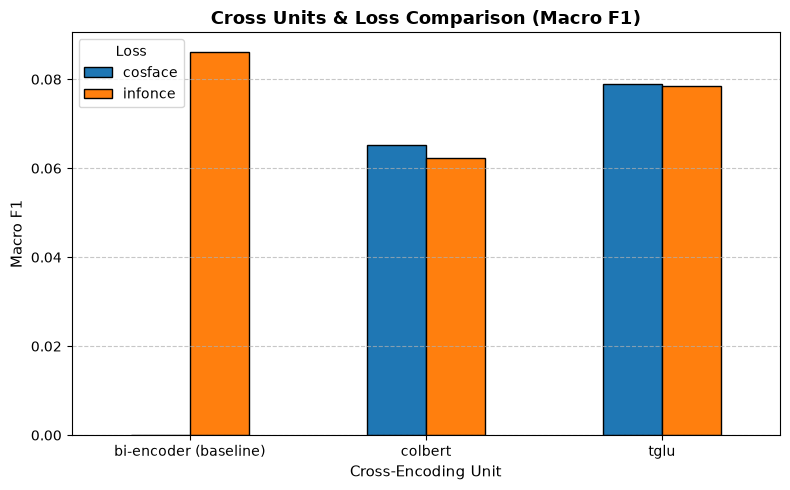

In [10]:
plot_df = df.dropna().reset_index()
pivot_plot = plot_df.pivot(index="unit", columns="loss", values="f1")

ax = pivot_plot.plot(kind="bar", figsize=(8, 5), rot=0, edgecolor="black")
plt.title("Cross Units & Loss Comparison (Macro F1)", fontsize=13, fontweight="bold")
plt.ylabel("Macro F1", fontsize=11)
plt.xlabel("Cross-Encoding Unit", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(title="Loss")
plt.tight_layout()
plt.show()